# Face Mask Classification

This is a CNN classification project.

The dataset has 20000 face images, 10000 with a mask and 10000 without a mask. I am training on CPU, so I use 2560 of those images at 128x128 instead of the full 224 set. The photos are grayscale and loaded as 3 channels.

I train two models on the same split. The first is a small CNN. The second is MobileNetV2 with ImageNet weights and a frozen base. I compare accuracy and F1, then save the transfer model.


In [1]:
%pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download("pranavsingaraju/facemask-detection-dataset-20000-images")
print("Path to dataset files:", path)


Note: you may need to restart the kernel to use updated packages.
Path to dataset files: C:\Users\Administrator\.cache\kagglehub\datasets\pranavsingaraju\facemask-detection-dataset-20000-images\versions\1


In [16]:
import os
import tensorflow as tf

tf.keras.utils.set_random_seed(42)


def find_named_dir(root, folder_name):
    for current, dirnames, _ in os.walk(root):
        if folder_name in dirnames:
            return os.path.join(current, folder_name)


mask_dir = find_named_dir(path, "new_with_mask")
DATASET_PATH = os.path.dirname(mask_dir)
class_names = sorted([f for f in os.listdir(DATASET_PATH) if os.path.isdir(os.path.join(DATASET_PATH, f))])
print("Dataset:", DATASET_PATH)
print(class_names)
for name in class_names:
    print(name, "->", len(os.listdir(os.path.join(DATASET_PATH, name))))


Dataset: C:\Users\Administrator\.cache\kagglehub\datasets\pranavsingaraju\facemask-detection-dataset-20000-images\versions\1
['new_with_mask', 'new_without_mask']
new_with_mask -> 10000
new_without_mask -> 10000


new_with_mask -> (224, 224) L
new_without_mask -> (224, 224) L


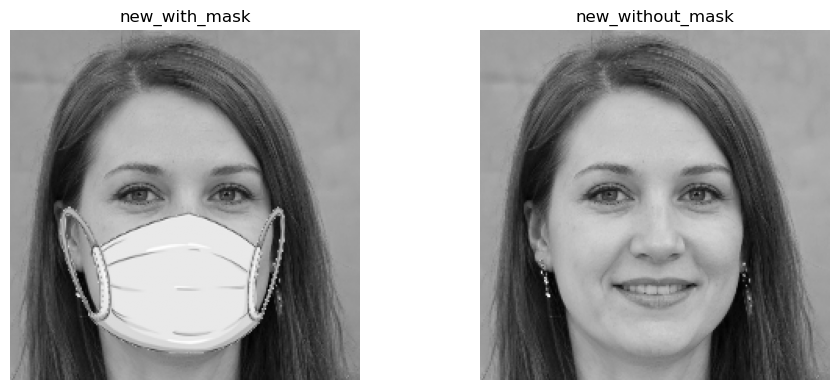

In [17]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(10, 4))
for i, class_name in enumerate(class_names):
    class_path = os.path.join(DATASET_PATH, class_name)
    image_path = os.path.join(class_path, os.listdir(class_path)[0])
    image = plt.imread(image_path)
    plt.subplot(1, len(class_names), i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(class_name)
    plt.axis("off")
    print(class_name, "->", Image.open(image_path).size, Image.open(image_path).mode)
plt.tight_layout()
plt.show()


In [20]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

full_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    color_mode="rgb",
    shuffle=True,
    seed=42,
)
class_names = full_ds.class_names
print(class_names)

full_ds = full_ds.shuffle(1000, seed=42, reshuffle_each_iteration=False)
subset = full_ds.take(150)
n = int(subset.cardinality().numpy())
train_ds = subset.take((n * 8) // 10).cache().prefetch(AUTOTUNE)
rest_ds = subset.skip((n * 8) // 10)
val_ds = rest_ds.take(n // 10).cache().prefetch(AUTOTUNE)
test_ds = rest_ds.skip(n // 10).cache().prefetch(AUTOTUNE)
print("batches", n, "train/val/test",
      int(train_ds.cardinality().numpy()),
      int(val_ds.cardinality().numpy()),
      int(test_ds.cardinality().numpy()))


Found 20000 files belonging to 2 classes.
['new_with_mask', 'new_without_mask']
batches 150 train/val/test 120 15 15


In [21]:
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

scratch_model = tf.keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1.0 / 255),
    layers.RandomFlip("horizontal"),
    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax"),
])
scratch_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
scratch_model.summary()
history_scratch = scratch_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
    verbose=1,
)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_3 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,714 (92.63 KB)

 Trainable params: 23,714 (92.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.5195 - loss: 0.6938 - val_accuracy: 0.5063 - val_loss: 0.6846
Epoch 2/5
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.6068 - loss: 0.6594 - val_accuracy: 0.9312 - val_loss: 0.5945
Epoch 3/5
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8130 - loss: 0.4690 - val_accuracy: 0.8479 - val_loss: 0.3512
Epoch 4/5
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9500 - loss: 0.1888 - val_accuracy: 0.9625 - val_loss: 0.1577
Epoch 5/5
120/120 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9586 - loss: 0.1258 - val_accuracy: 0.9125 - val_loss: 0.2151


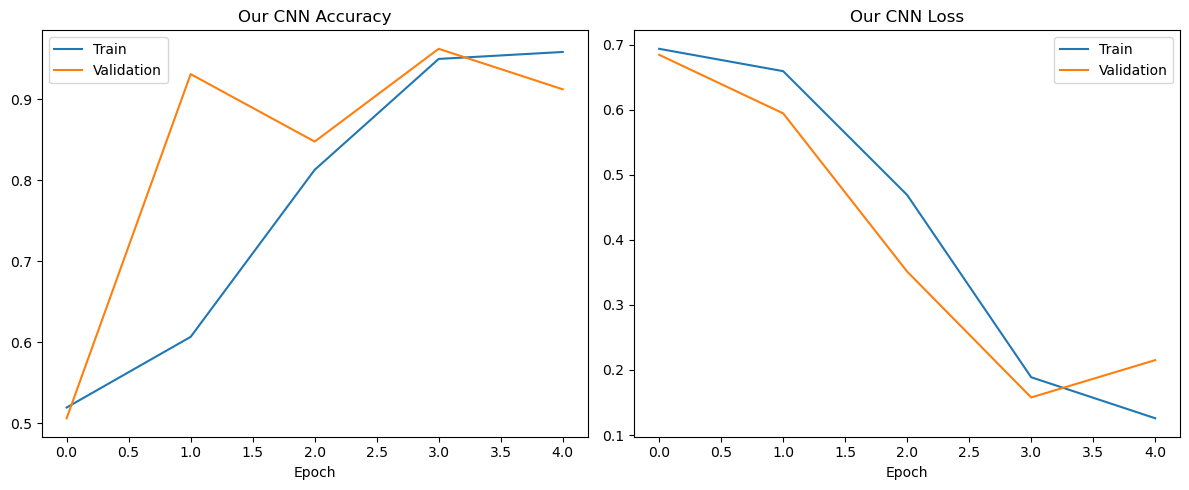

In [22]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_scratch.history["accuracy"], label="Train")
plt.plot(history_scratch.history["val_accuracy"], label="Validation")
plt.title("Our CNN Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_scratch.history["loss"], label="Train")
plt.plot(history_scratch.history["val_loss"], label="Validation")
plt.title("Our CNN Loss")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.show()


Our CNN
Accuracy : 0.9625
Precision: 0.9651679841897233
Recall   : 0.9625
F1       : 0.9624765559877744
                  precision    recall  f1-score   support

   new_with_mask       1.00      0.93      0.96       245
new_without_mask       0.93      1.00      0.96       235

        accuracy                           0.96       480
       macro avg       0.96      0.96      0.96       480
    weighted avg       0.97      0.96      0.96       480



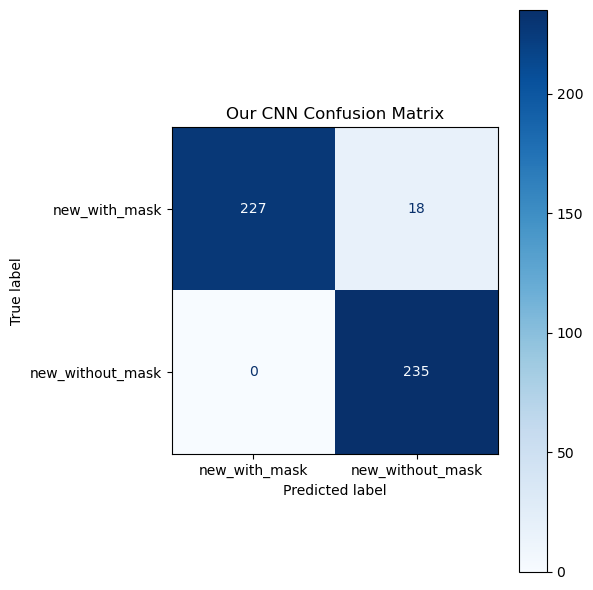

In [23]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score

test_images = np.concatenate([batch[0].numpy() for batch in test_ds])
y_true_scratch = np.concatenate([batch[1].numpy().argmax(axis=1) for batch in test_ds])
y_pred_scratch = scratch_model.predict(test_images, verbose=0).argmax(axis=1)

scratch_acc = accuracy_score(y_true_scratch, y_pred_scratch)
scratch_precision = precision_score(y_true_scratch, y_pred_scratch, average="weighted", zero_division=0)
scratch_recall = recall_score(y_true_scratch, y_pred_scratch, average="weighted", zero_division=0)
scratch_f1 = f1_score(y_true_scratch, y_pred_scratch, average="weighted", zero_division=0)

print("Our CNN")
print("Accuracy :", scratch_acc)
print("Precision:", scratch_precision)
print("Recall   :", scratch_recall)
print("F1       :", scratch_f1)
print(classification_report(y_true_scratch, y_pred_scratch, target_names=class_names, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(
    confusion_matrix(y_true_scratch, y_pred_scratch),
    display_labels=class_names,
).plot(ax=ax, cmap="Blues")
plt.title("Our CNN Confusion Matrix")
plt.tight_layout()
plt.show()


## Transfer Learning

MobileNetV2 is the transfer model. The base stays frozen and only the new head is trained, so this run stays short on CPU. The grayscale photos are already loaded as 3 channels, which is what the ImageNet weights expect.


In [24]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(128, 128, 3))
base_model.trainable = False

inputs = layers.Input(shape=(128, 128, 3))
x = layers.RandomFlip("horizontal")(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)
model.summary()


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_4 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [25]:
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=4,
    callbacks=[EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
    verbose=1,
)


Epoch 1/4


c:\Users\Administrator\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


120/120 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.9958 - loss: 0.0158 - val_accuracy: 1.0000 - val_loss: 6.5799e-04
Epoch 2/4
120/120 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - accuracy: 1.0000 - loss: 6.3028e-04 - val_accuracy: 1.0000 - val_loss: 3.4094e-04
Epoch 3/4
120/120 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - accuracy: 1.0000 - loss: 3.1211e-04 - val_accuracy: 1.0000 - val_loss: 2.3805e-04
Epoch 4/4
120/120 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - accuracy: 1.0000 - loss: 2.3171e-04 - val_accuracy: 1.0000 - val_loss: 1.7612e-04


In [26]:
print("Frozen MobileNet best val accuracy", max(history.history["val_accuracy"]))


Frozen MobileNet best val accuracy 1.0


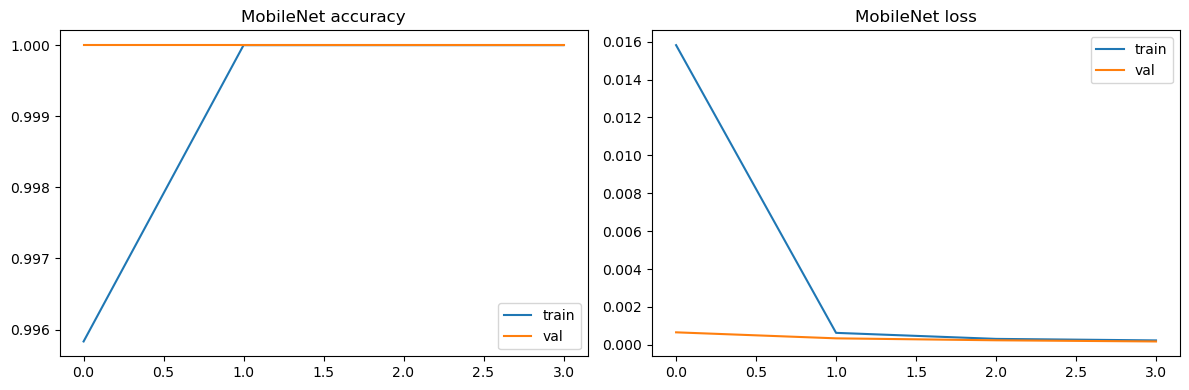

In [27]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("MobileNet accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("MobileNet loss")
plt.legend()
plt.tight_layout()
plt.show()


Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1       : 1.0
                  precision    recall  f1-score   support

   new_with_mask       1.00      1.00      1.00       245
new_without_mask       1.00      1.00      1.00       235

        accuracy                           1.00       480
       macro avg       1.00      1.00      1.00       480
    weighted avg       1.00      1.00      1.00       480



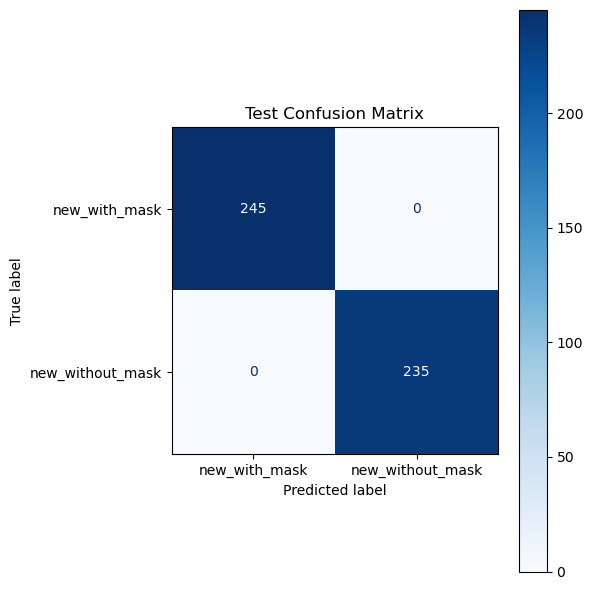

In [28]:
y_true = y_true_scratch
y_pred = model.predict(test_images, verbose=0).argmax(axis=1)

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, average="weighted", zero_division=0))
print("Recall   :", recall_score(y_true, y_pred, average="weighted", zero_division=0))
print("F1       :", f1_score(y_true, y_pred, average="weighted", zero_division=0))
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(ax=ax, cmap="Blues")
plt.title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

transfer_acc = accuracy_score(y_true, y_pred)
transfer_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)


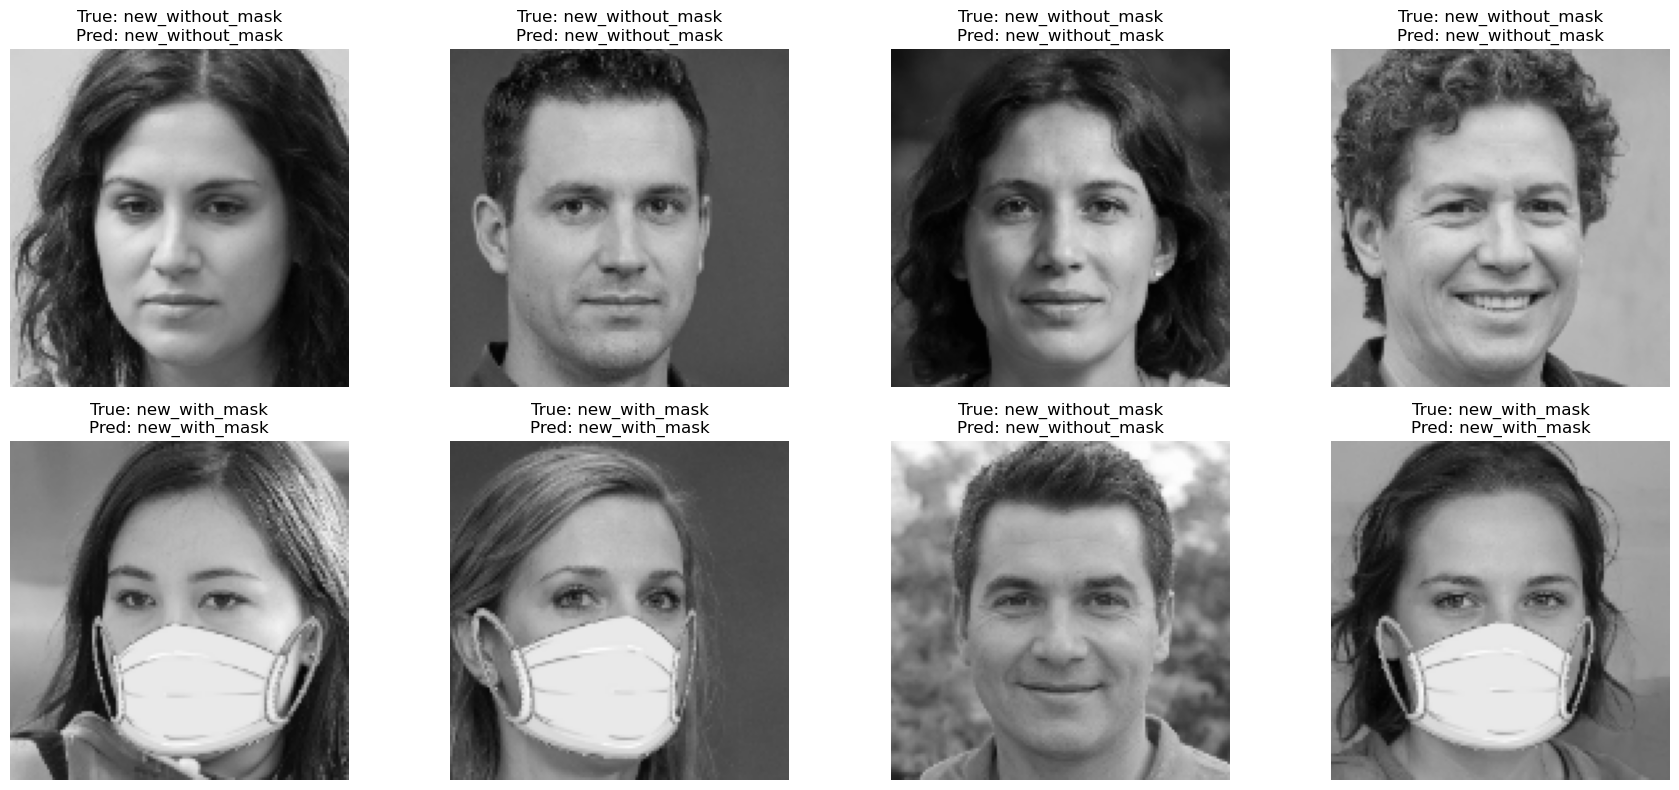

In [29]:
images, labels = next(iter(test_ds))
pred = model.predict(images, verbose=0)

plt.figure(figsize=(18, 8))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    actual = class_names[np.argmax(labels[i])]
    guessed = class_names[np.argmax(pred[i])]
    plt.title("True: " + actual + "\nPred: " + guessed)
    plt.axis("off")
plt.tight_layout()
plt.show()


## Comparison


In [30]:
print("Our CNN   Accuracy:", round(scratch_acc, 4), " F1:", round(scratch_f1, 4))
print("Transfer  Accuracy:", round(transfer_acc, 4), " F1:", round(transfer_f1, 4))


Our CNN   Accuracy: 0.9625  F1: 0.9625
Transfer  Accuracy: 1.0  F1: 1.0


In [31]:
model.save("facemask.keras")


# Conclusion

The full set has 20000 images. This run uses 2560 of them at 128x128 so it can finish on CPU. The small CNN is trained from scratch. MobileNetV2 keeps the ImageNet base frozen and trains only the new head. Accuracy and F1 on the same test batches are in the comparison cell. The saved model says whether the person is wearing a mask. It does not draw a box around the face. The file is facemask.keras.
